In [ ]:
from pathlib import Path
import copy, json, random, sys

import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from xgboost import XGBRegressor
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "house-price.csv"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
raw = pd.read_csv(DATA, keep_default_na=False, na_values=[""])
raw.columns = raw.columns.str.strip()
for c in raw.select_dtypes("object"):
    raw[c] = raw[c].str.strip()
target = "SalePrice"
numeric = raw.select_dtypes(include=np.number).columns.tolist()
categorical = raw.select_dtypes(exclude=np.number).columns.tolist()
summary = pd.DataFrame(
    {
        "value": [
            raw.shape[0],
            raw.shape[1],
            len(numeric) - 1,
            len(categorical),
            raw.duplicated().sum(),
            raw[target].isna().sum(),
            raw[target].min(),
            raw[target].median(),
            raw[target].mean(),
            raw[target].max(),
        ]
    },
    index=[
        "rows",
        "columns",
        "numeric predictors",
        "categorical predictors",
        "duplicate rows",
        "missing target",
        "target min",
        "target median",
        "target mean",
        "target max",
    ],
)
display(summary)
missing = raw.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].to_frame("blank_missing"))
print(
    "Regression target valid:",
    pd.api.types.is_numeric_dtype(raw[target])
    and raw[target].notna().all()
    and raw[target].gt(0).all(),
)
print(
    "Impossible garage years:",
    raw.loc[
        raw["Garage Yr Blt"].gt(raw["Yr Sold"]), ["Garage Yr Blt", "Yr Sold"]
    ].to_dict("records"),
)
q1, q3 = raw[target].quantile([0.25, 0.75])
print(
    "Target IQR flags:",
    ((raw[target] < q1 - 1.5 * (q3 - q1)) | (raw[target] > q3 + 1.5 * (q3 - q1))).sum(),
)

,value
rows,2930.000000
columns,82.000000
numeric predictors,38.000000
categorical predictors,43.000000
duplicate rows,0.000000
missing target,0.000000
target min,12789.000000
target median,160000.000000
target mean,180796.060068
target max,755000.000000


,blank_missing
Lot Frontage,490
Garage Yr Blt,159
Mas Vnr Area,23
Mas Vnr Type,23
Bsmt Exposure,4
Garage Finish,2
BsmtFin Type 2,2
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Qual,1


Regression target valid: True
Impossible garage years: [{'Garage Yr Blt': 2008.0, 'Yr Sold': 2007}, {'Garage Yr Blt': 2207.0, 'Yr Sold': 2007}]
Target IQR flags: 137


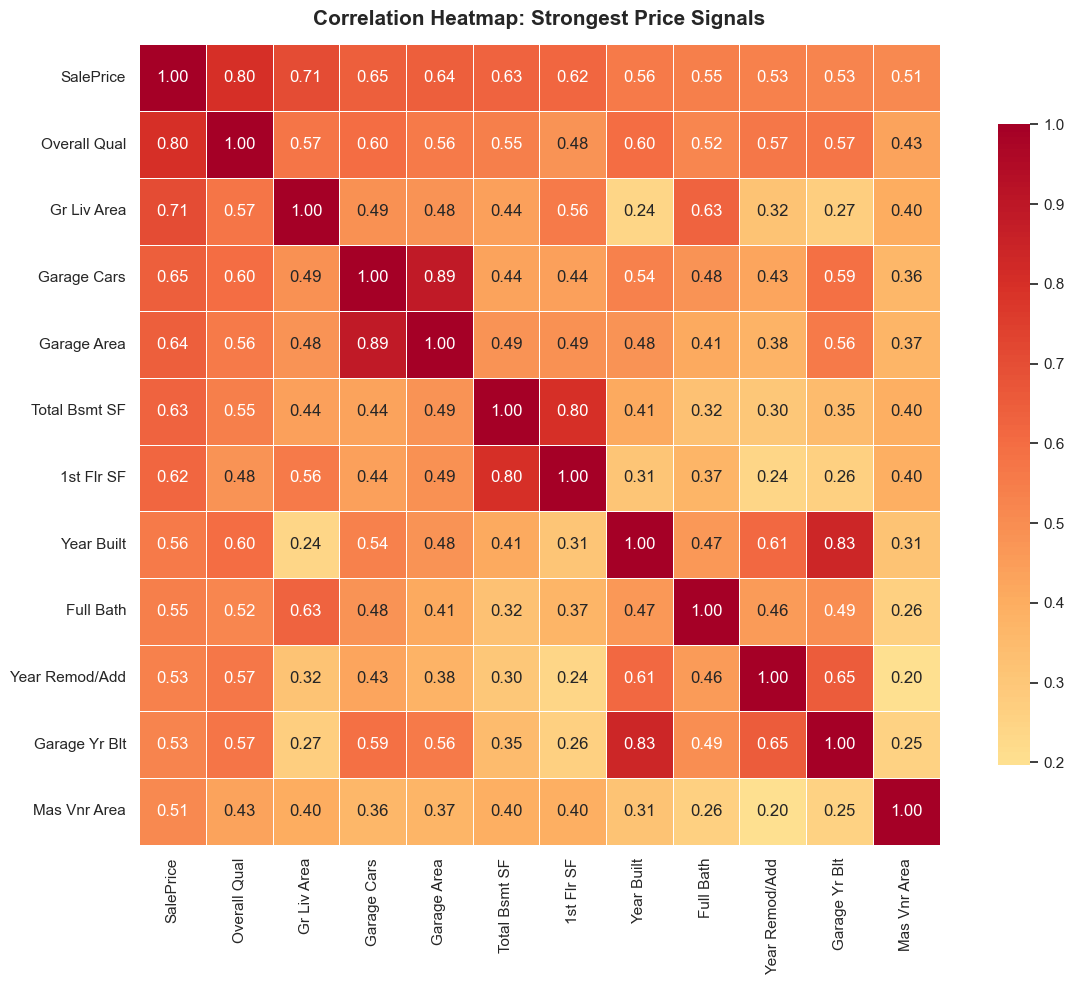

In [3]:
numeric_data = raw.select_dtypes(include=np.number)
correlations = numeric_data.corr()["SalePrice"].abs().sort_values(ascending=False)
heatmap_columns = correlations.head(12).index
plt.figure(figsize=(13, 10))
sns.heatmap(
    numeric_data[heatmap_columns].corr(), cmap="RdYlBu_r", center=0,
    annot=True, fmt=".2f", square=True, linewidths=0.4,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Heatmap: Strongest Price Signals", fontsize=15, weight="bold", pad=14)
plt.tight_layout()
plt.show()


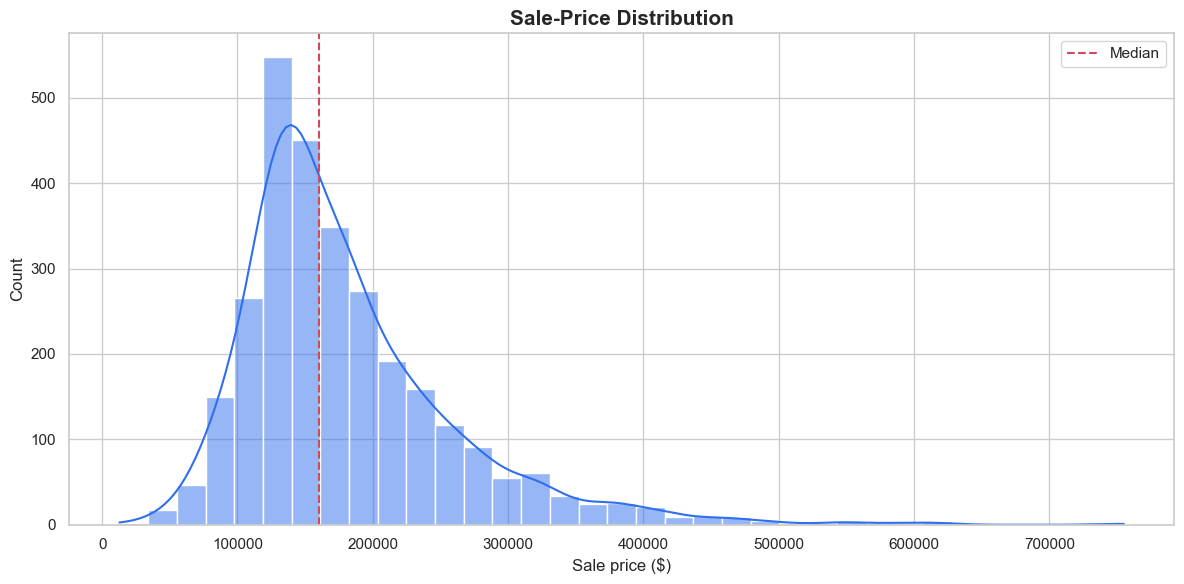

In [4]:
plt.figure(figsize=(12, 6))
sns.histplot(raw["SalePrice"], bins=35, kde=True, color="#2F6FED")
plt.axvline(raw["SalePrice"].median(), color="#D1495B", linestyle="--", label="Median")
plt.title("Sale-Price Distribution", fontsize=15, weight="bold")
plt.xlabel("Sale price ($)")
plt.legend()
plt.tight_layout()
plt.show()


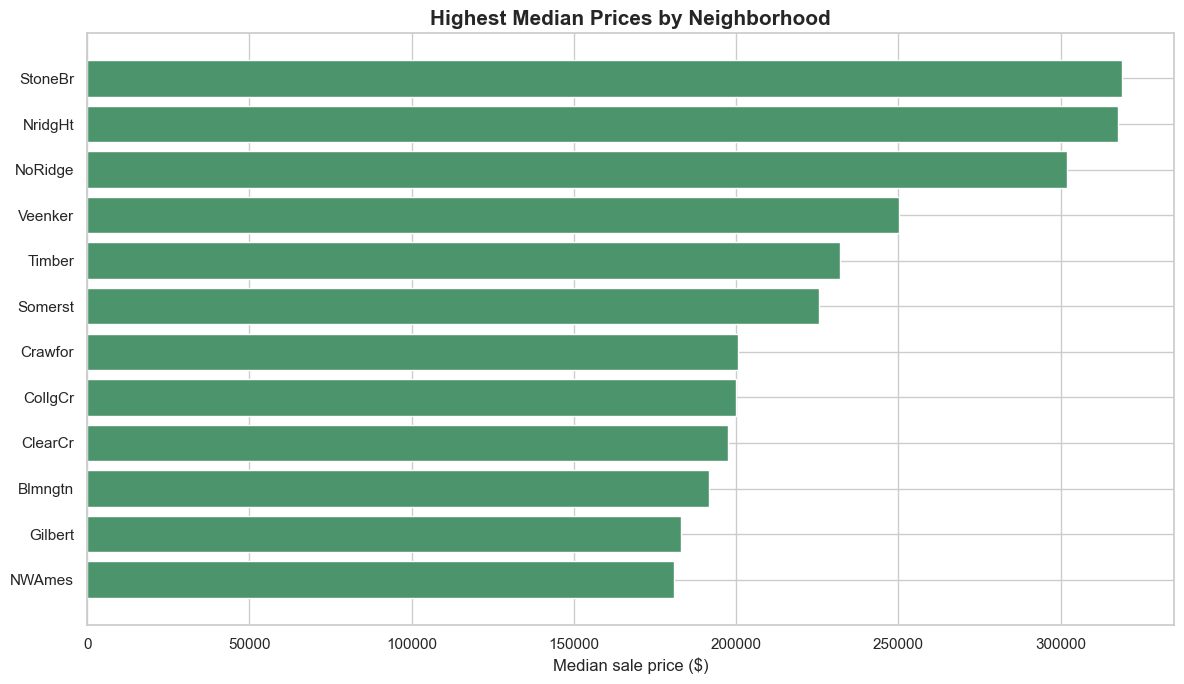

In [5]:
neighborhood_prices = (
    raw.groupby("Neighborhood")["SalePrice"].agg(["median", "count"])
    .query("count >= 20").nlargest(12, "median").sort_values("median")
)
plt.figure(figsize=(12, 7))
plt.barh(neighborhood_prices.index, neighborhood_prices["median"], color="#4C956C")
plt.title("Highest Median Prices by Neighborhood", fontsize=15, weight="bold")
plt.xlabel("Median sale price ($)")
plt.tight_layout()
plt.show()


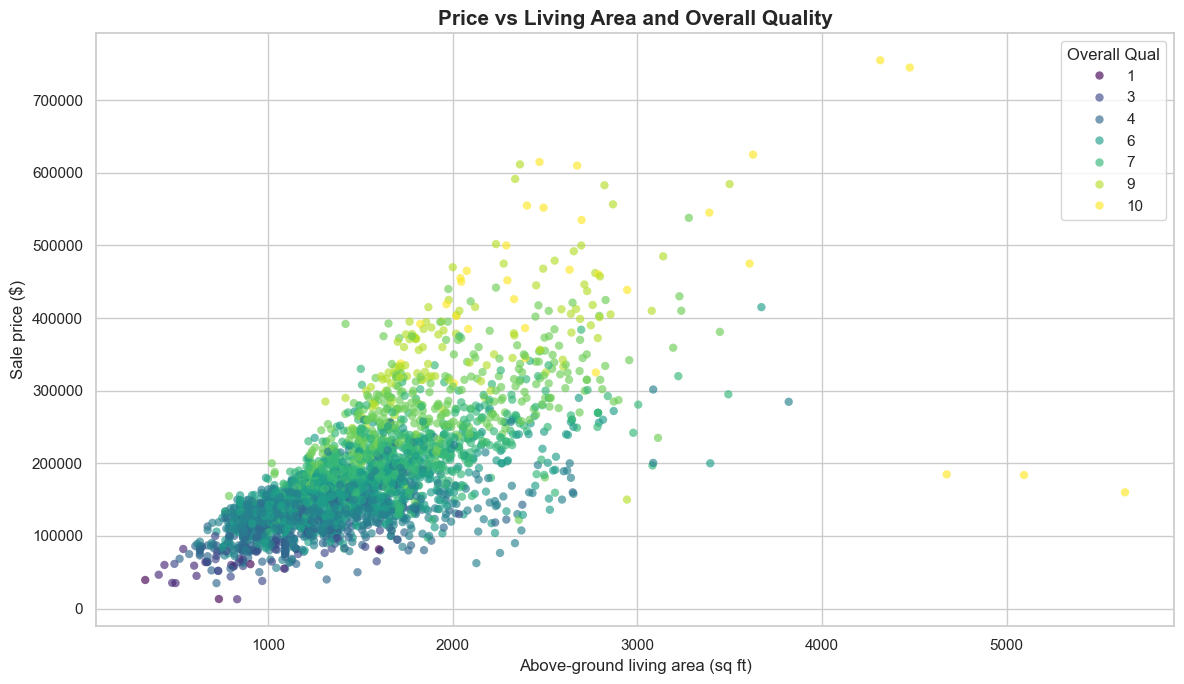

In [6]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=raw, x="Gr Liv Area", y="SalePrice", hue="Overall Qual",
    palette="viridis", alpha=0.65, linewidth=0,
)
plt.title("Price vs Living Area and Overall Quality", fontsize=15, weight="bold")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.tight_layout()
plt.show()


In [7]:
display(correlations.drop("SalePrice").head(10).rename("absolute_correlation").to_frame())


,absolute_correlation
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974
Garage Yr Blt,0.526965


In [ ]:
from models.ames_features import AmesFeatures, get_feature_defaults

clean = raw.drop_duplicates().reset_index(drop=True)
y = clean.pop(target).astype(float)
X = clean.drop(columns=["Order", "PID"])
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.15 / 0.85, random_state=SEED
)
feature_defaults = get_feature_defaults(X_train)
probe = AmesFeatures().fit_transform(X_train)
num_cols = probe.select_dtypes(include=np.number).columns
cat_cols = probe.select_dtypes(exclude=np.number).columns
preprocessor = Pipeline(
    [
        ("features", AmesFeatures()),
        (
            "columns",
            ColumnTransformer(
                [
                    (
                        "num",
                        Pipeline(
                            [
                                (
                                    "impute",
                                    SimpleImputer(
                                        strategy="median", add_indicator=True
                                    ),
                                ),
                                ("scale", RobustScaler()),
                            ]
                        ),
                        num_cols,
                    ),
                    (
                        "cat",
                        Pipeline(
                            [
                                ("impute", SimpleImputer(strategy="most_frequent")),
                                (
                                    "encode",
                                    OneHotEncoder(
                                        handle_unknown="ignore",
                                        sparse_output=False,
                                        min_frequency=2,
                                    ),
                                ),
                            ]
                        ),
                        cat_cols,
                    ),
                ],
                verbose_feature_names_out=False,
            ),
        ),
    ]
)
Xt = preprocessor.fit_transform(X_train)
Xv = preprocessor.transform(X_val)
Xs = preprocessor.transform(X_test)
yt = np.log1p(y_train.to_numpy())
yv = np.log1p(y_val.to_numpy())
selector = SelectKBest(f_regression, k=min(128, Xt.shape[1])).fit(Xt, yt)
Xtd = selector.transform(Xt).astype("float32")
Xvd = selector.transform(Xv).astype("float32")
Xsd = selector.transform(Xs).astype("float32")
print(
    "split:",
    len(X_train),
    len(X_val),
    len(X_test),
    "transformed:",
    Xt.shape,
    "deep features:",
    Xtd.shape[1],
)


In [ ]:
class MLP(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class TabNet(nn.Module):
    def __init__(self, n, h=128, steps=3):
        super().__init__()
        self.steps = steps
        self.att = nn.ModuleList([nn.Linear(n, n) for _ in range(steps)])
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Linear(n, h), nn.BatchNorm1d(h), nn.GELU(), nn.Dropout(0.15)
                )
                for _ in range(steps)
            ]
        )
        self.head = nn.Linear(h, 1)

    def forward(self, x):
        prior = torch.ones_like(x)
        total = 0
        for a, b in zip(self.att, self.blocks):
            mask = torch.softmax(a(x) * prior, 1)
            total = total + b(mask * x)
            prior = prior * (1.5 - mask)
        return self.head(total / self.steps).squeeze(1)


class FTTransformer(nn.Module):
    def __init__(self, n, d=16):
        super().__init__()
        self.w = nn.Parameter(torch.randn(n, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n, d))
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(
            d, 4, d * 2, 0.15, batch_first=True, activation="gelu", norm_first=True
        )
        self.enc = nn.TransformerEncoder(layer, 1)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))

    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        cls = self.cls.expand(len(x), -1, -1)
        return self.head(self.enc(torch.cat([cls, tok], 1))[:, 0]).squeeze(1)


def train_torch(model, X, y, Xval, yval, epochs=100, patience=14):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    loader = DataLoader(
        TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.float32)),
        128,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    lossfn = nn.SmoothL1Loss()
    xv = torch.tensor(Xval, device=device)
    yvt = torch.tensor(yval, dtype=torch.float32, device=device)
    best = (1e9, None, 0)
    wait = 0
    hist = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = lossfn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5)
            opt.step()
            losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vl = lossfn(model(xv), yvt).item()
        hist.append((np.mean(losses), vl))
        sched.step(vl)
        if vl < best[0] - 1e-6:
            best = (vl, copy.deepcopy(model.state_dict()), epoch)
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break
    model.load_state_dict(best[1])
    model.eval()
    model.best_epoch = best[2]
    model.history = hist
    return model


def torch_predict(model, X):
    with torch.no_grad():
        return (
            model(torch.tensor(X, device=next(model.parameters()).device)).cpu().numpy()
        )

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        max_features=0.8,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=SEED,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=1200,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=SEED,
    ),
}
for name, m in models.items():
    print("training", name)
    m.fit(Xt, yt)
deep = {
    "MLP": train_torch(MLP(Xtd.shape[1]), Xtd, yt, Xvd, yv),
    "TabNet": train_torch(TabNet(Xtd.shape[1]), Xtd, yt, Xvd, yv),
    "FT-Transformer": train_torch(FTTransformer(Xtd.shape[1]), Xtd, yt, Xvd, yv),
}
for name, m in deep.items():
    models[name] = m
    print(name, "best epoch", m.best_epoch + 1)

In [ ]:
def pred(name, m, split):
    z = {"train": Xt, "validation": Xv, "test": Xs}[split]
    zd = {"train": Xtd, "validation": Xvd, "test": Xsd}[split]
    p = torch_predict(m, zd) if name in deep else m.predict(z)
    return np.maximum(0, np.expm1(p))


ys = {
    "train": y_train.to_numpy(),
    "validation": y_val.to_numpy(),
}
rows = []
for name, m in models.items():
    for split in ["train", "validation"]:
        p = pred(name, m, split)
        mse = mean_squared_error(ys[split], p)
        rows.append(
            {
                "Model": name,
                "Split": split,
                "MAE": mean_absolute_error(ys[split], p),
                "MSE": mse,
                "RMSE": np.sqrt(mse),
                "R2": r2_score(ys[split], p),
            }
        )
metrics = pd.DataFrame(rows)
validation_comparison = (
    metrics.query("Split=='validation'")
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)
display(
    validation_comparison.style.format(
        {"MAE": "{:,.0f}", "MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"}
    )
)
pivot = metrics.pivot(index="Model", columns="Split", values="RMSE")
pivot["Validation gap %"] = (pivot["validation"] / pivot["train"] - 1) * 100
display(pivot.sort_values("validation").style.format("{:,.1f}"))
plt.figure(figsize=(11, 5))
sns.barplot(data=metrics, x="Model", y="RMSE", hue="Split")
plt.xticks(rotation=25)
plt.title("Train vs validation RMSE")
plt.tight_layout()
plt.show()
best_name = validation_comparison.iloc[0]["Model"]
best = models[best_name]
test_pred = pred(best_name, best, "test")
test_mse = mean_squared_error(y_test, test_pred)
test_metrics = {
    "Model": best_name,
    "Split": "test",
    "MAE": mean_absolute_error(y_test, test_pred),
    "MSE": test_mse,
    "RMSE": np.sqrt(test_mse),
    "R2": r2_score(y_test, test_pred),
}
metrics = pd.concat([metrics, pd.DataFrame([test_metrics])], ignore_index=True)
comparison = pd.DataFrame([test_metrics])
display(
    comparison.style.format(
        {"MAE": "{:,.0f}", "MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"}
    )
)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test, y=test_pred, ax=ax[0])
lim = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
ax[0].plot(lim, lim, "--", color="black")
ax[0].set(
    xlabel="Actual", ylabel="Predicted", title=f"{best_name}: actual vs predicted"
)
residual = y_test.to_numpy() - test_pred
sns.scatterplot(x=test_pred, y=residual, ax=ax[1])
ax[1].axhline(0, ls="--", color="black")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residual diagnostics")
plt.tight_layout()
plt.show()
print(f"Selected on validation RMSE: {best_name}; test metrics shown for the selected model only.")

In [ ]:
comparison.to_csv(MODELS / "model_comparison.csv", index=False)
metrics.to_csv(MODELS / "all_split_metrics.csv", index=False)
bundle = {
    "model_name": best_name,
    "model": best,
    "preprocessor": preprocessor,
    "selector": selector if best_name in deep else None,
    "deep": best_name in deep,
    "raw_columns": X.columns.tolist(),
    "feature_defaults": feature_defaults,
    "log_target": True,
}
joblib.dump(bundle, MODELS / "best_house_price_model.joblib")
metadata = {
    "best_model": best_name,
    "seed": SEED,
    "rows": len(raw),
    "splits": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "metrics": comparison.to_dict("records"),
}
(MODELS / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Best model: {best_name}")
print("Saved:", MODELS / "best_house_price_model.joblib")

,Feature,Importance
2,Overall Qual,0.125030
34,TotalSF,0.076908
198,Exter Qual_TA,0.074721
253,Central Air_Y,0.052955
252,Central Air_N,0.035720
41,HasFireplace,0.031285
210,Bsmt Qual_Ex,0.030250
24,Garage Cars,0.029885
35,TotalBathrooms,0.027087
300,Paved Drive_N,0.022617


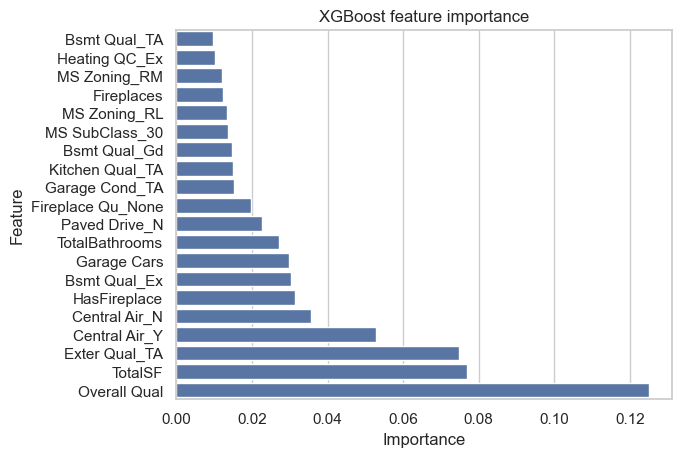

In [9]:
feature_names = preprocessor.named_steps["columns"].get_feature_names_out()
if hasattr(best, "feature_importances_"):
    imp = pd.DataFrame(
        {"Feature": feature_names, "Importance": best.feature_importances_}
    ).nlargest(20, "Importance")
    display(imp)
    sns.barplot(data=imp.sort_values("Importance"), x="Importance", y="Feature")
    plt.title(f"{best_name} feature importance")
    plt.show()
elif hasattr(best, "coef_"):
    imp = pd.DataFrame(
        {"Feature": feature_names, "Importance": np.abs(best.coef_)}
    ).nlargest(20, "Importance")
    display(imp)
else:
    print(
        "Neural winner: use permutation importance on the validation set; native scalar feature importance is not claimed."
    )

In [ ]:
HOUSE_INPUT = {
    "Overall Qual": 7,
    "Overall Cond": 5,
    "Gr Liv Area": 1800,
    "Lot Area": 10000,
    "Year Built": 2000,
    "Total Bsmt SF": 1000,
    "Garage Cars": 2,
    "Full Bath": 2,
    "Neighborhood": "NAmes",
}


def predict_house(user_values):
    bundle = joblib.load(MODELS / "best_house_price_model.joblib")

    unknown_fields = set(user_values) - set(bundle["raw_columns"])
    if unknown_fields:
        raise ValueError(f"Unknown fields: {sorted(unknown_fields)}")

    base = {}
    for column in bundle["raw_columns"]:
        training_column = X_train[column]
        if pd.api.types.is_numeric_dtype(training_column):
            base[column] = training_column.median()
        else:
            modes = training_column.mode()
            base[column] = modes.iloc[0] if not modes.empty else "None"

    valid_neighborhoods = sorted(X_train["Neighborhood"].dropna().unique())
    neighborhood = user_values.get("Neighborhood")
    if neighborhood not in valid_neighborhoods:
        raise ValueError(
            "Neighborhood must be one of: " + ", ".join(valid_neighborhoods)
        )

    base.update(user_values)
    house = pd.DataFrame([base])
    transformed = bundle["preprocessor"].transform(house)

    if bundle["deep"]:
        transformed = bundle["selector"].transform(transformed).astype("float32")
        log_prediction = torch_predict(bundle["model"], transformed)[0]
    else:
        log_prediction = bundle["model"].predict(transformed)[0]

    predicted_price = max(0, float(np.expm1(log_prediction)))
    print(f"Model used: {bundle['model_name']}")
    print("House values used:")
    display(pd.DataFrame([user_values]))
    print(f"Predicted house price: ${predicted_price:,.2f}")
    return predicted_price


predicted_price = predict_house(HOUSE_INPUT)